# Investigate alleles that increased abundance

Almost all variants with abundance changes that surpass assay variability are decreases in abundance. For the very few cases that increased abundance, we want to see if there is anything biologically interesting going on here.

In [1]:
import polars as pl
import sys
import seaborn as sns
from matplotlib import pyplot as plt
import pandas as pd
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [52]:
outputs_dir = "../3_outputs"
scores = pl.read_csv(f"{outputs_dir}/annotated_perturbation_scores.csv", infer_schema_length=1000000)

symbol_medians = scores.filter(~pl.col("dualipa_abun_score").is_null()).group_by("symbol").agg(
    pl.col("dualipa_abun_score").mean().alias("gene_mean")
).sort("gene_mean")

symbol_order = symbol_medians.select('symbol').to_series().to_list()
scores_plot = scores.join(symbol_medians, on="symbol").to_pandas()
scores_plot['symbol'] = pd.Categorical(scores_plot['symbol'], categories=symbol_order, ordered=True)
dual_ipa_df_orig = pl.DataFrame(scores_plot).with_columns(
    pl.col("clinvar_clnsig_clean").replace("6_No_ClinVar", "5_Others").alias("clinvar_clnsig_clean")
)
dual_ipa_df_orig.shape

(804, 567)

In [35]:
g2p_annot_df = pl.read_csv(
    "../../../1_allele_collection/3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules_with_protein_features.tsv", 
    separator="\t", infer_schema_length=10000
).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
)
# g2p_annot_df

In [53]:
dual_ipa_df = dual_ipa_df_orig.join(
    g2p_annot_df.select(["orf_id","mut_id"]+[c for c in g2p_annot_df.columns if c not in dual_ipa_df_orig.columns]),
    on=["orf_id","mut_id"],
    how="left"
)

## 1. Variants with increased abundance

In [37]:
incr_abun = scores.filter((pl.col("dualipa_abun_change")=="Y")&(pl.col("dualipa_abun_chg_dir")=="Increase"))
print(incr_abun.select(['symbol', 'aa_change', 'dualipa_abun_score', 'clinvar_clnsig_clean', 'StarStatus']))

shape: (20, 5)
┌────────┬───────────┬────────────────────┬──────────────────────┬────────────┐
│ symbol ┆ aa_change ┆ dualipa_abun_score ┆ clinvar_clnsig_clean ┆ StarStatus │
│ ---    ┆ ---       ┆ ---                ┆ ---                  ┆ ---        │
│ str    ┆ str       ┆ f64                ┆ str                  ┆ f64        │
╞════════╪═══════════╪════════════════════╪══════════════════════╪════════════╡
│ SH3BP2 ┆ Gly420Arg ┆ 2.335735           ┆ 1_Pathogenic         ┆ null       │
│ NAA10  ┆ Arg116Trp ┆ 2.654036           ┆ 1_Pathogenic         ┆ 2.0        │
│ MID1   ┆ Pro151Leu ┆ 3.449523           ┆ 4_VUS                ┆ 1.0        │
│ PKP2   ┆ Pro156Ala ┆ 2.210308           ┆ 4_VUS                ┆ 2.0        │
│ KLHL3  ┆ Glu85Ala  ┆ 3.952288           ┆ 1_Pathogenic         ┆ null       │
│ …      ┆ …         ┆ …                  ┆ …                    ┆ …          │
│ PKP2   ┆ Thr263Met ┆ 2.55075            ┆ 4_VUS                ┆ 2.0        │
│ KLHL3  ┆ Met78Val  ┆ 2.

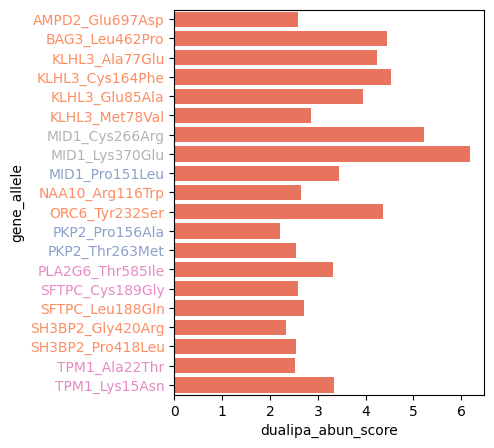

In [38]:
incr_abun_pd = incr_abun.sort("gene_allele").to_pandas()
fig, ax = plt.subplots(figsize=(4, 5))
sns.barplot(
    data=incr_abun_pd,
    x="dualipa_abun_score",
    y="gene_allele",
    ax=ax,
    color="tomato"
)

# Get the y-tick labels and corresponding clinvar values
y_labels = ax.get_yticklabels()
for i, label in enumerate(y_labels):
   gene_allele = label.get_text()
   clinvar_value = incr_abun_pd[incr_abun_pd['gene_allele'] == gene_allele]['clinvar_clnsig_clean'].iloc[0]
   color = palette_dict["clinvar_clnsig_clean"].get(clinvar_value, 'black')
   label.set_color(color)

plt.show()

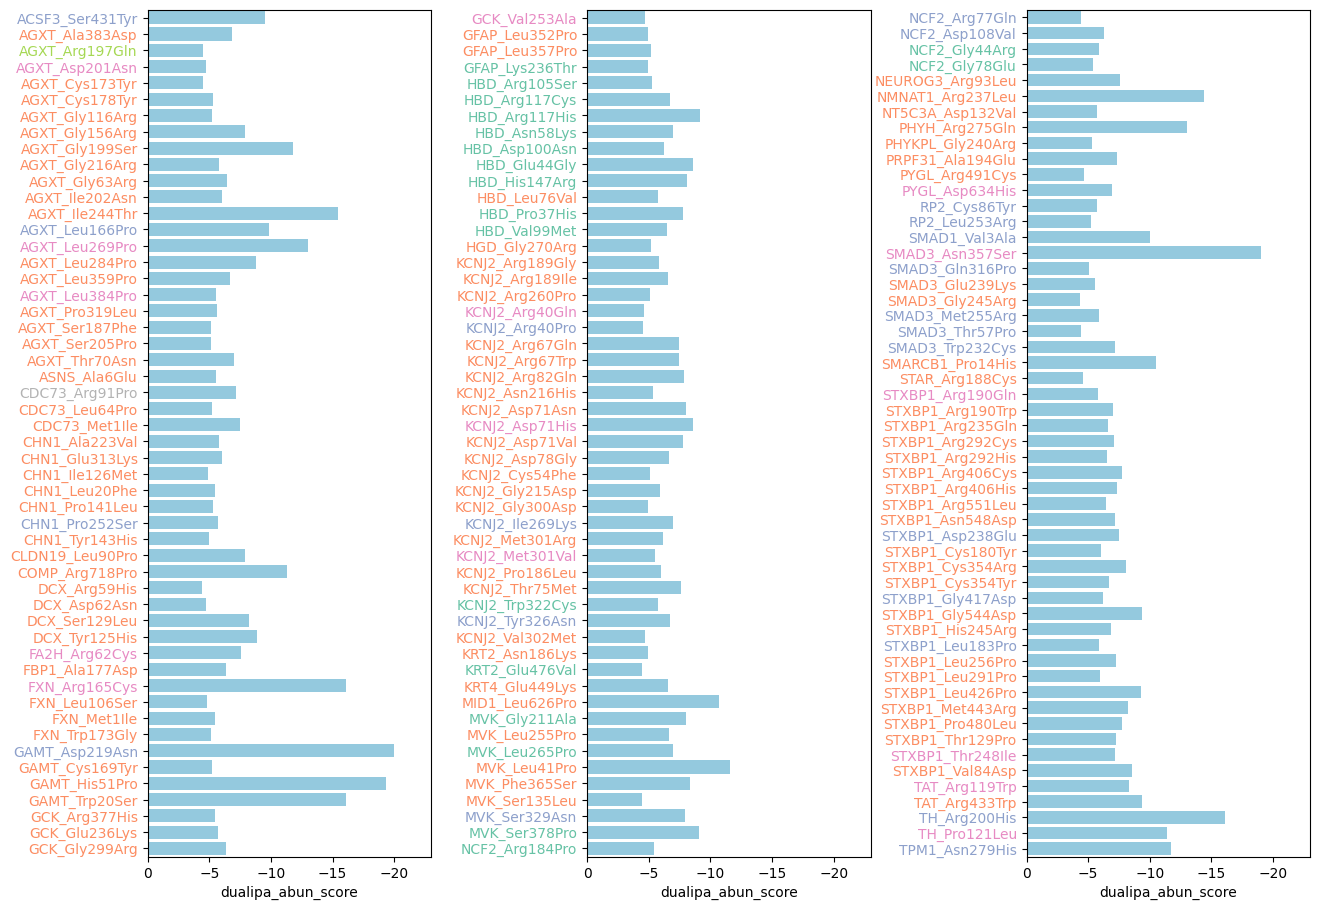

In [39]:
decr_abun = scores.filter((pl.col("dualipa_abun_change")=="Y")&(pl.col("dualipa_abun_chg_dir")=="Decrease"))
# print(decr_abun.select(['symbol', 'aa_change', 'dualipa_abun_score', 'clinvar_clnsig_clean', 'StarStatus']))

decr_abun_pd = decr_abun.sort("gene_allele").to_pandas()
# decr_abun_pd_inverted = decr_abun_pd.copy()
# decr_abun_pd_inverted['dualipa_abun_score'] = -decr_abun_pd_inverted['dualipa_abun_score']

pd_lists = [decr_abun_pd.iloc[:decr_abun_pd.shape[0]//3,:], 
            decr_abun_pd.iloc[decr_abun_pd.shape[0]//3:decr_abun_pd.shape[0]//3*2,:], 
            decr_abun_pd.iloc[decr_abun_pd.shape[0]//3*2:,:]
]
fig, axes = plt.subplots(1, 3, figsize=(15, 11))

for i, ax in enumerate(axes.flatten()):
    sub_df = pd_lists[i]
    # display(sub_df)
    sns.barplot(
        data=sub_df,
        x="dualipa_abun_score",
        y="gene_allele",
        ax=ax,
        color="skyblue"
    )
    # Get the y-tick labels and corresponding clinvar values
    y_labels = ax.get_yticklabels()
    for i, label in enumerate(y_labels):
       gene_allele = label.get_text()
       clinvar_value = sub_df[sub_df['gene_allele'] == gene_allele]['clinvar_clnsig_clean'].iloc[0]
       color = palette_dict["clinvar_clnsig_clean"].get(clinvar_value, 'black')
       label.set_color(color)
        
    # Optional: Invert the x-axis to show negative values on the right
    ax.set_xlim(-23, 0)
    ax.invert_xaxis()
    ax.set_ylabel("")

plt.subplots_adjust(wspace=0.55)
plt.show()

## 2. Group the variants by gene

<Figure size 640x480 with 0 Axes>

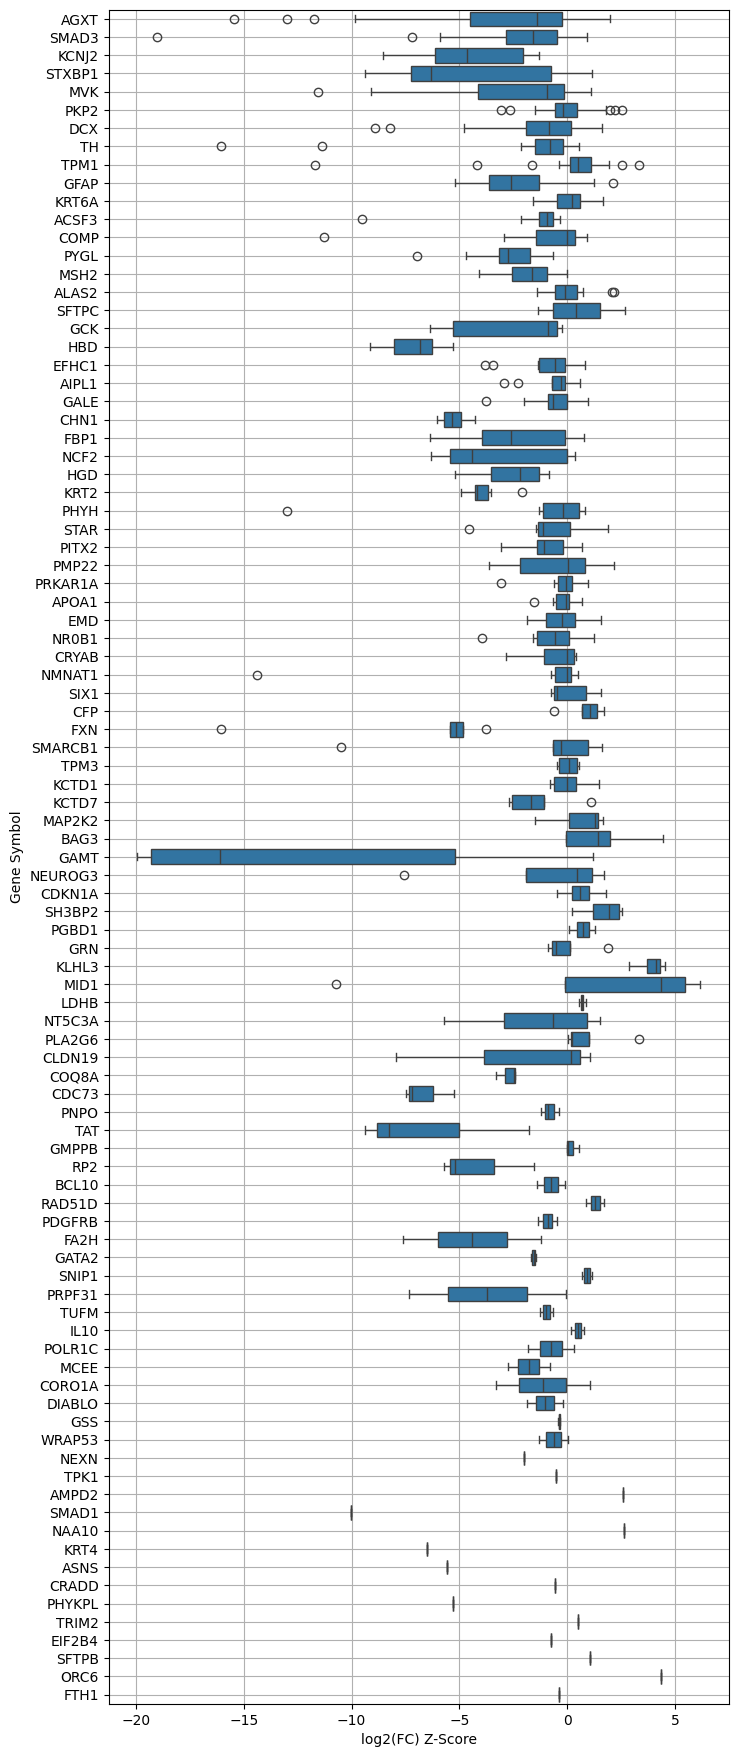

In [40]:
dual_gene = dual_ipa_df.group_by(
    ["symbol"]
).len().rename(
    {"len": "total_counts_all"}
).sort("total_counts_all", descending=True)

plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 22))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", ax=ax, order=dual_gene["symbol"])
ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

In [41]:
# plt.clf()
# fig, ax = plt.subplots(1,1,figsize=(8, 30))
# sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
#             palette=palette_dict["clinvar_clnsig_clean"], ax=ax, 
#             hue="clinvar_clnsig_clean", 
#             hue_order=sorted(scores_plot.dropna(subset="clinvar_clnsig_clean")["clinvar_clnsig_clean"].unique()),
#             gap=.2,
#             fliersize=2,
#             order=dual_gene["symbol"]
#            )

# ax.set_xlabel("log2(FC) Z-Score")
# ax.set_ylabel("Gene Symbol")
# ax.grid()
# plt.show()

In [42]:
# plt.clf()
# fig, ax = plt.subplots(1,1,figsize=(8, 30))
# sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
#             ax=ax, 
#             hue="pLDDT_Category", 
#             hue_order=sorted(scores_plot.dropna(subset="pLDDT_Category")["pLDDT_Category"].unique()),
#             gap=.2,
#             fliersize=2,
#             order=dual_gene["symbol"]
#            )

# ax.set_xlabel("log2(FC) Z-Score")
# ax.set_ylabel("Gene Symbol")
# ax.grid()
# plt.show()

In [43]:
# plt.clf()
# fig, ax = plt.subplots(1,1,figsize=(8, 30))
# sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
#             ax=ax, 
#             hue="RSA_Category", 
#             hue_order=sorted(scores_plot.dropna(subset="RSA_Category")["RSA_Category"].unique()),
#             gap=.2,
#             fliersize=2,
#             order=dual_gene["symbol"]
#            )

# ax.set_xlabel("log2(FC) Z-Score")
# ax.set_ylabel("Gene Symbol")
# ax.grid()
# plt.show()

## 3. Plot hits

In [45]:
dual_ipa_df_clean_hit = dual_ipa_df.with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("dualipa_hit")
)

dual_ipa_df_metric = dual_ipa_df_clean_hit.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
).with_columns(
    pl.col("inheritance_pattern").fill_null("unknown")
)

# Create abundance change categories
df_processed = dual_ipa_df_metric.with_columns([
    pl.when(
        (pl.col("dualipa_abun_change") == "Y") & (pl.col("dualipa_abun_chg_dir") == "Increase")
    ).then(pl.lit("Increase"))
    .when(
        (pl.col("dualipa_abun_change") == "Y") & (pl.col("dualipa_abun_chg_dir") == "Decrease")
    ).then(pl.lit("Decrease"))
    .when(pl.col("dualipa_abun_change") == "N").then(pl.lit("No Significant Change"))
    .when(pl.col("dualipa_abun_change") == "Uncertain").then(pl.lit("Uncertain"))
    .alias("abundance_category")
])

### 3.1 Plot hits by ClinVar

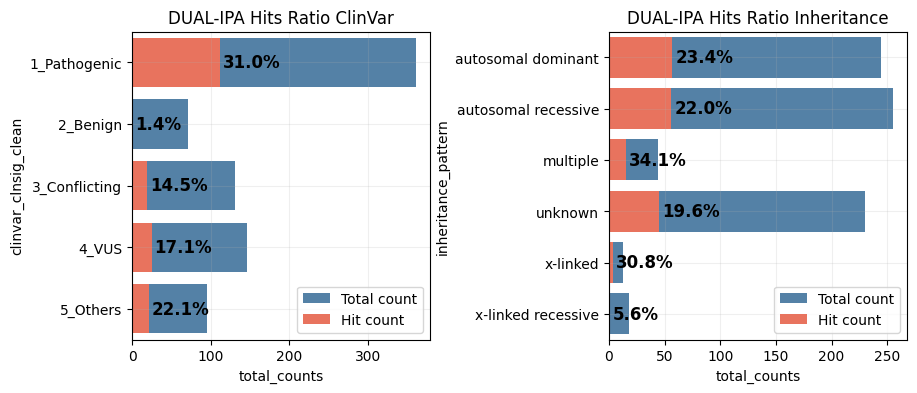

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
plot_assay_hit_by_category(dual_ipa_df_metric, "dualipa_hit", "clinvar_clnsig_clean", f"DUAL-IPA Hits Ratio ClinVar", ax=axes[0])
plot_assay_hit_by_category(dual_ipa_df_metric, "dualipa_hit", "inheritance_pattern", f"DUAL-IPA Hits Ratio Inheritance", ax=axes[1])
plt.subplots_adjust(wspace=.6)
plt.show()

In [47]:
dual_ipa_df_metric.with_columns([
    pl.when(
        (pl.col("dualipa_abun_change") == "Y") & (pl.col("dualipa_abun_chg_dir") == "Increase")
    ).then(pl.lit("Increase"))
    .when(
        (pl.col("dualipa_abun_change") == "Y") & (pl.col("dualipa_abun_chg_dir") == "Decrease")
    ).then(pl.lit("Decrease"))
    .when(pl.col("dualipa_abun_change") == "N").then(pl.lit("No Significant Change"))
    .when(pl.col("dualipa_abun_change") == "Uncertain").then(pl.lit("Uncertain"))
    .alias("abundance_category")
])

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat,allele_wt_log2fc,zscore_log2fc_mean_norm_by_all_wt_mean,allele_wt_log2fc_pvalue,zscore_log2fc_mean_norm_by_each_wt,symbol_right,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change_right,aa_change_right,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,…,protein_00000739-a-1 outliers⁺⁺,protein_00001087-a-1 avg,protein_00001087-a-1 outliers⁺⁺,protein_00001053-a-1 avg,protein_00001053-a-1 outliers⁺⁺,protein_00001032-a-1 avg,protein_00001032-a-1 outliers⁺⁺,protein_00001033-a-1 avg,protein_00001033-a-1 outliers⁺⁺,protein_00001034-a-1 avg,protein_00001034-a-1 outliers⁺⁺,protein_00000959-a-1 avg,protein_00000959-a-1 outliers⁺⁺,protein_00001177-a-1 avg,protein_00001177-a-1 outliers⁺⁺,protein_00000001-d-2 avg,protein_00000001-d-2 outliers⁺⁺,protein_00000966-a-1 avg,protein_00000966-a-1 outliers⁺⁺,protein_00000013-a-1 avg,protein_00000013-a-1 outliers⁺⁺,protein_00000101-a-1 avg,protein_00000101-a-1 outliers⁺⁺,protein_00000102-0-1 avg,protein_00000102-0-1 outliers⁺⁺,protein_00000745-a-1 avg,protein_00000745-a-1 outliers⁺⁺,protein_00000746-a-1 avg,protein_00000746-a-1 outliers⁺⁺,protein_00001065-a-1 avg,protein_00001065-a-1 outliers⁺⁺,protein_00000686-a-1 avg,protein_00000686-a-1 outliers⁺⁺,protein_00001112-a-1 avg,protein_00001112-a-1 outliers⁺⁺,dualipa_hit,abundance_category
cat,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,…,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,str,str,f64,str,bool,str
"""KCNJ2""","""allele""","""821A>T""","""Asp274Val""",11,"""H06""","""11_H06""",4976,100016069,2638,true,1736.815259,5002.388278,0.851111,1.862762,0.456908,-1.775144,-1,-1.130024,-4.834053,0.000001,-3.08904,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008340""","""ALE00008326""","""NC_000017.11:70175860:A:T""","""821A>T""","""Asp274Val""","""Edgotyping3""","""VUSMutGDEh010""","""D06""","""GDEhDisVCh_40005""","""C10""",1.0,"""VUSMutGDDh010""","""D06""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,false,"""Uncertain"""
"""PKP2""","""allele""","""1415A>G""","""Lys472Arg""",19,"""F05""","""19_F05""",2900,54308,3072,true,960.198308,1368.839077,0.887373,0.924631,0.959706,-0.247815,0,-0.059336,-0.181273,0.856153,-0.18025,"""PKP2""","""ENSG00000057294""","""CCSBVarC008023""","""ALE00008009""","""NC_000012.12:32841169:T:C""","""1415A>G""","""Lys472Arg""","""Edgotyping3""","""VUSMutGDEh015""","""H02""","""GDEhDisVCh_40015""","""E08""",1.0,"""VUSMutGDDh015""","""H02""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,false,"""No Significant Change"""
"""KCNJ2""","""allele""","""899G>A""","""Gly300Asp""",11,"""D07""","""11_D07""",8822,100016069,2641,true,1801.536166,6450.702463,0.526546,1.862762,0.282669,-2.304423,-2,-1.822812,-7.844631,4.3423e-15,-4.97117,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008343""","""ALE00008329""","""NC_000017.11:70175938:G:A""","""899G>A""","""Gly300Asp""","""Edgotyping3""","""VUSMutGDEh010""","""G06""","""GDEhDisVCh_40005""","""F10""",1.0,"""VUSMutGDDh010""","""G06""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,true,"""Decrease"""
"""HBD""","""allele""","""174C>A""","""Asn58Lys""",26,"""E05""","""26_E05""",9609,13796,218146,true,43.352592,5031.259545,0.020272,0.118448,0.171143,-2.643204,-2,-2.546728,-10.990479,4.2467

In [64]:
def plot_dualipa_by_cat(df_processed, category, clinvar_categories=None, ax=None):
   # Count occurrences
   summary_df = df_processed.group_by([category, "abundance_category"]).len().sort([category, "abundance_category"])
   # Get total counts per clinvar category for percentage calculation
   total_counts = df_processed.group_by(category).len().rename({"len": "total_count"})
   
   # Join and calculate percentages
   summary_with_pct = summary_df.join(total_counts, on=category).with_columns([
       (pl.col("len") / pl.col("total_count") * 100).round(1).alias("percentage")
   ])
   # Convert to pandas for plotting
   plot_df = summary_with_pct.to_pandas()
   # Color palette for abundance categories
   abundance_colors = {
       'Increase': '#e74c3c',      # Red
       'Decrease': '#3498db',      # Blue  
       'No Significant Change': '#95a5a6',  # Gray
       'Uncertain': '#f39c12'      # Orange
   }
   if clinvar_categories is None:
       clinvar_categories = plot_df[category].unique()
       
   # Create the plot
   if ax is None:
       fig, ax = plt.subplots(figsize=(len(clinvar_categories)*2.5, 4))
   
   x_pos = range(len(clinvar_categories))
   
   # Plot bars for each abundance category
   bar_width = 0.18
   bar_gap = 0.02  # Gap between bars within the same category
   abundance_cats = ['Decrease', 'Increase', 'No Significant Change', 'Uncertain']

   max_height = 0
   for i, cat in enumerate(abundance_cats):
       cat_data = plot_df[plot_df['abundance_category'] == cat]
       
       # Align data with clinvar categories (fill missing with 0)
       counts = []
       percentages = []
       for clinvar_cat in clinvar_categories:
           row = cat_data[cat_data[category] == clinvar_cat]
           if len(row) > 0:
               counts.append(row['len'].iloc[0])
               percentages.append(row['percentage'].iloc[0])
           else:
               counts.append(0)
               percentages.append(0.0)
       
       # Plot bars with percentages as height
       bars = ax.bar([x + i * (bar_width + bar_gap) for x in x_pos], percentages, 
                     bar_width, label=cat, color=abundance_colors[cat], alpha=0.8)

       # Add count labels on bars
       for j, (bar, count, pct) in enumerate(zip(bars, counts, percentages)):
           if pct > 0:
               height = bar.get_height()
               max_height = max(max_height, height)
               ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                      f'{count}', ha='center', va='bottom', fontsize=9, fontweight='bold')
   
   # Customize the plot
   ax.set_xlabel(category, fontsize=12, fontweight='bold')
   ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold')
   ax.set_title(f'DUAL-IPA Abundance Change by {category}', fontsize=14, fontweight='bold')
   ax.set_xticks([x + bar_width * 1.5 for x in x_pos])
   ax.set_xticklabels(clinvar_categories, rotation=0, ha='center')
   ax.legend(title='Abundance Change', loc='best')
   ax.grid(axis='y', alpha=0.3)
   ax.set_ylim(0, max_height+5)
   
   plt.tight_layout()
   plt.show()
   
   # Print summary statistics
   # print("Summary Statistics:")
   # with pl.Config(set_tbl_rows=25):
   #     display(summary_with_pct)

   return summary_with_pct

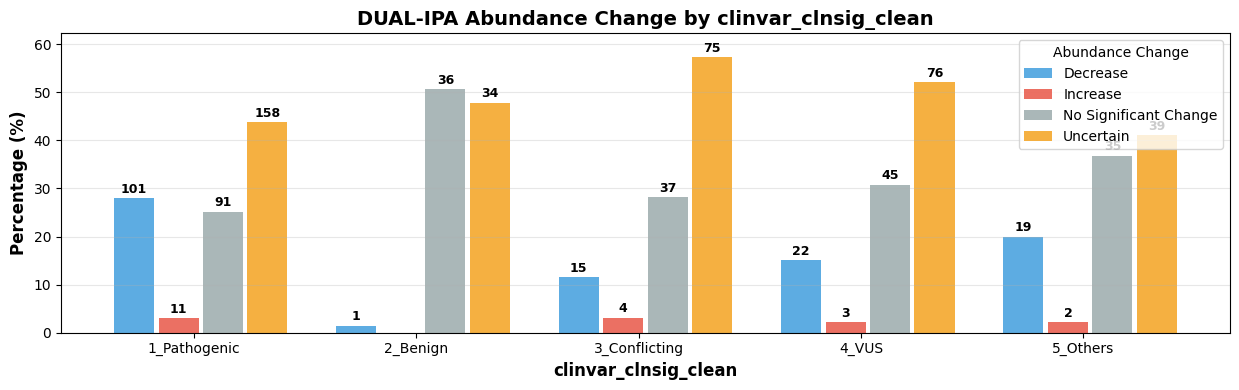

clinvar_clnsig_clean,abundance_category,len,total_count,percentage
str,str,u32,u32,f64
"""1_Pathogenic""","""Decrease""",101,361,28.0
"""1_Pathogenic""","""Increase""",11,361,3.0
"""1_Pathogenic""","""No Significant Change""",91,361,25.2
"""1_Pathogenic""","""Uncertain""",158,361,43.8
"""2_Benign""","""Decrease""",1,71,1.4
…,…,…,…,…
"""4_VUS""","""Uncertain""",76,146,52.1
"""5_Others""","""Decrease""",19,95,20.0
"""5_Others""","""Increase""",2,95,2.1


In [62]:
plot_dualipa_by_cat(df_processed, "clinvar_clnsig_clean")

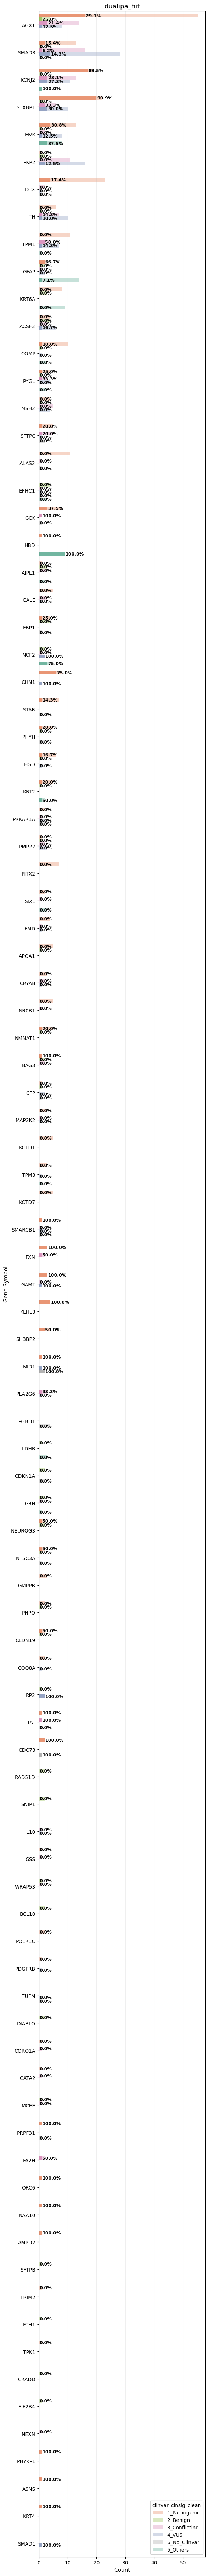

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,55,16,29.090909,81
1,AGXT,2_Benign,4,1,25.000000,81
2,AGXT,3_Conflicting,14,3,21.428571,81
3,AGXT,4_VUS,8,1,12.500000,81
4,SMAD3,1_Pathogenic,13,2,15.384615,59
...,...,...,...,...,...,...
223,NEXN,3_Conflicting,1,0,0.000000,1
224,PHYKPL,1_Pathogenic,1,1,100.000000,1
225,ASNS,1_Pathogenic,1,1,100.000000,1
226,KRT4,1_Pathogenic,1,1,100.000000,1


In [147]:
plot_gene_level_summary(
    assay_df=dual_ipa_df_clean_hit,
    # .filter(
    #     pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    # ),
    assay="dualipa_hit",
    cat="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"]
)

### 3.2 Plot hits by structural info

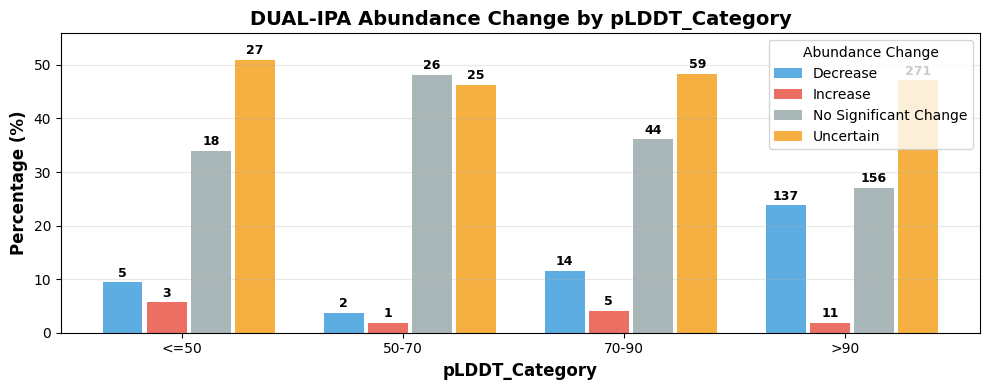

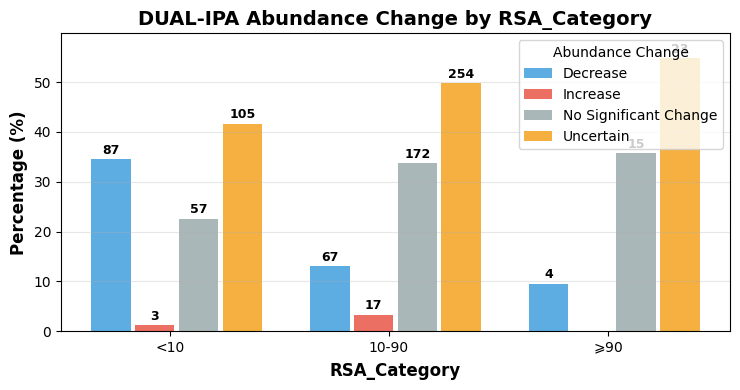

In [63]:
plot_dualipa_by_cat(df_processed, "pLDDT_Category", ["<=50", "50-70", "70-90", ">90"])
_ = plot_dualipa_by_cat(df_processed, "RSA_Category", ["<10", "10-90", '$\\geqslant$90'])

protein_Acetylation (4, 907)
protein_Amino acid properties (8, 907)


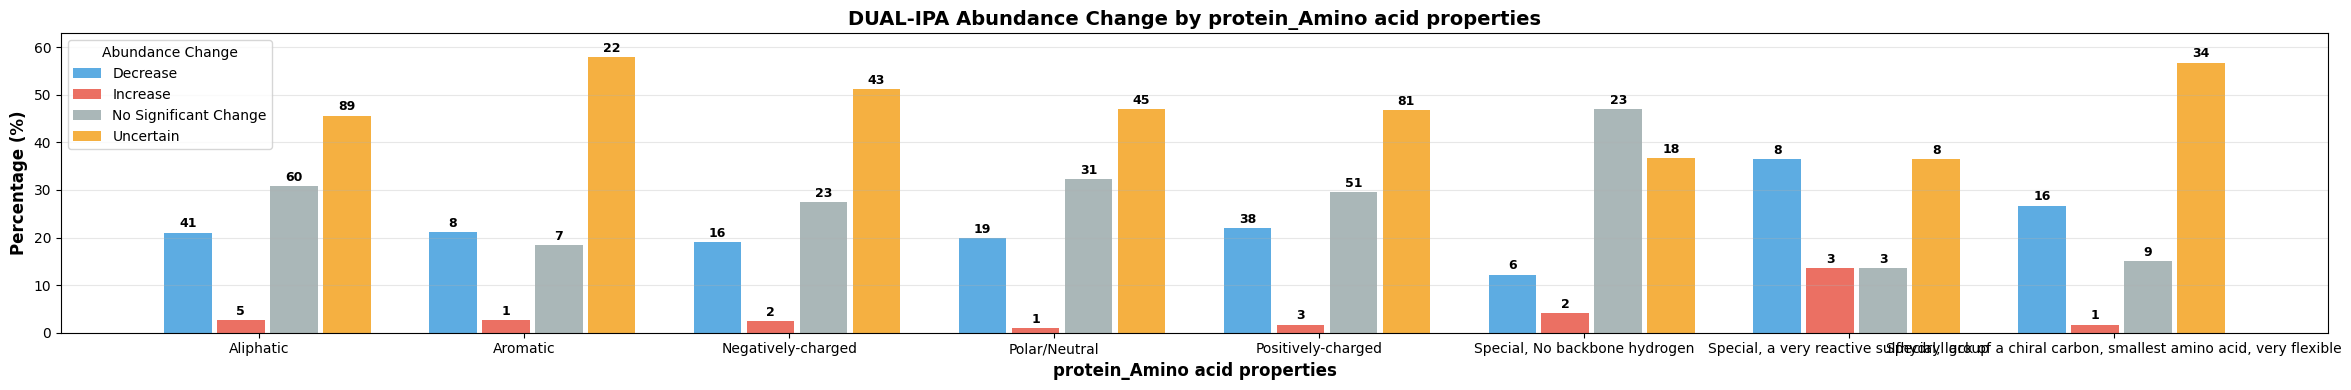

protein_Binding site (UniProt) (9, 907)


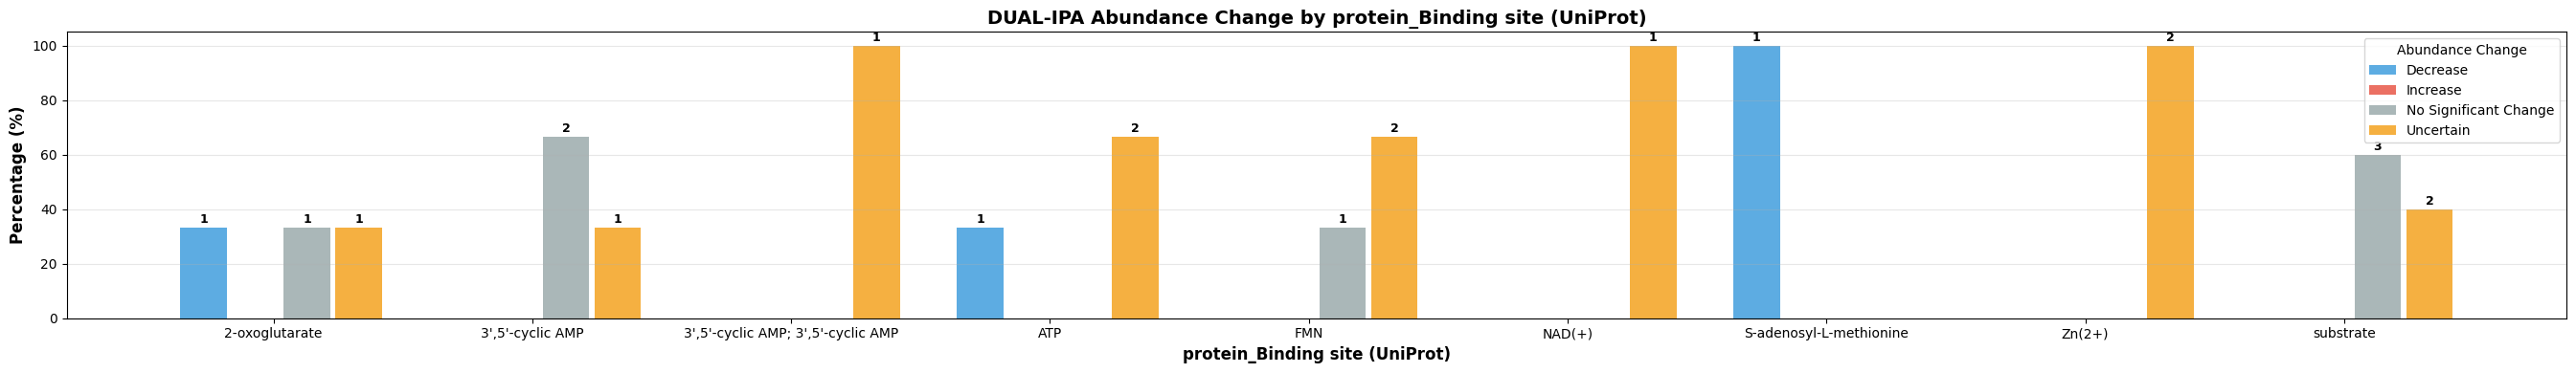

protein_Compositional bias (UniProt) (3, 907)
protein_Disulfide bond (UniProt) (2, 907)
protein_Inter-chain Salt bridge (PDB) (8, 907)
protein_Methylation (5, 907)
protein_Modified residue (UniProt) (6, 907)
protein_Motif (UniProt) (2, 907)
protein_Regulatory sites (2, 907)
protein_Secondary structure (DSSP 3-state)* (3, 907)


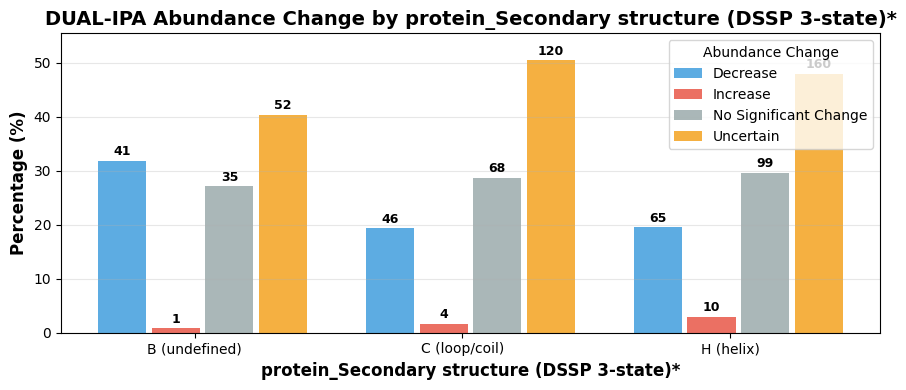

protein_Secondary structure (DSSP 9-state)* (9, 907)


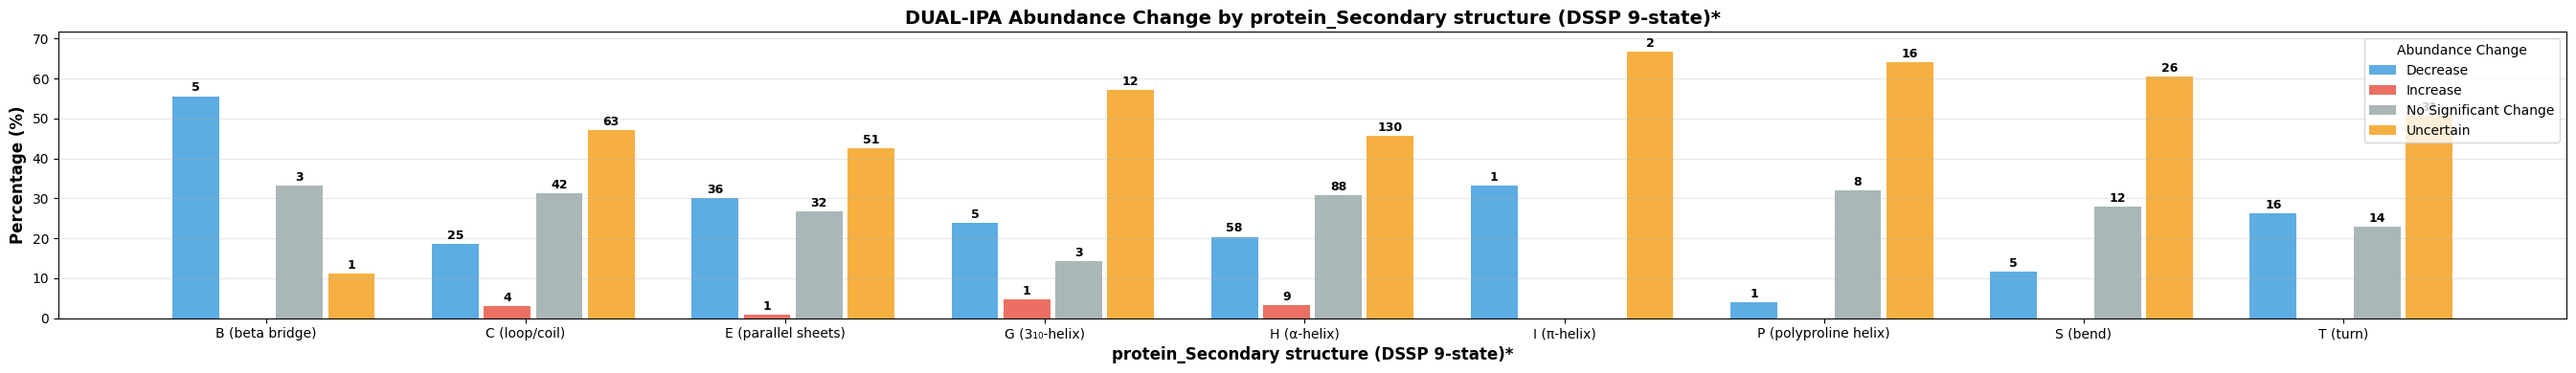

protein_Secondary structure (PDBe/SIFTS) (3, 907)


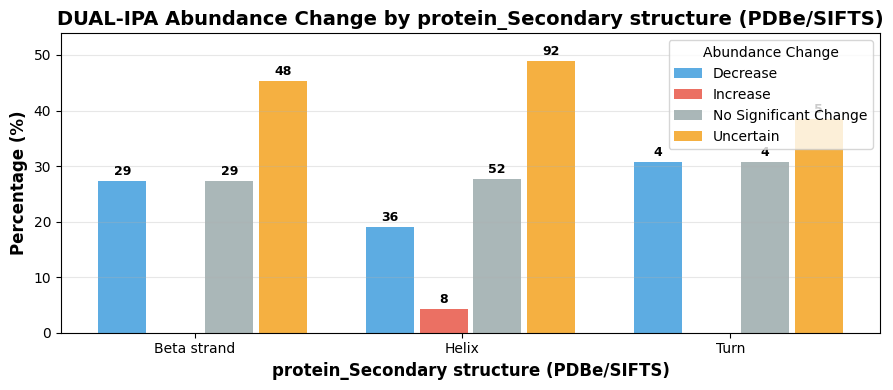

protein_Sequence conflict (UniProt) (3, 907)
protein_Topological domain (UniProt) (2, 907)


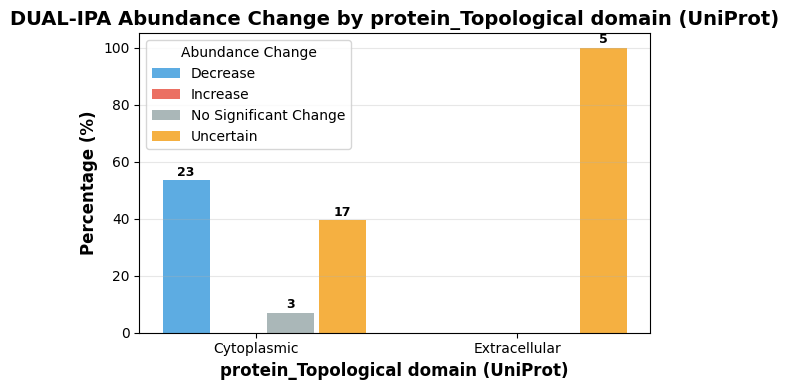

protein_Transit peptide (UniProt) (2, 907)
protein_Transmembrane (UniProt) (3, 907)
protein_Ubiquitination (7, 907)
protein_Zinc finger (UniProt) (4, 907)


In [65]:
for c in [c for c in g2p_annot_df.columns if c not in dual_ipa_df_orig.columns]:
    if dual_ipa_df.drop_nulls(c).unique(c).shape[0] > 1 and dual_ipa_df.drop_nulls(c).unique(c).shape[0] < 10 and not c.startswith("protein_000"):
        # print(c, dual_ipa_df.drop_nulls(c).unique(c).shape)
        if dual_ipa_df.drop_nulls(c).shape[0] > 20:
            fig, ax = plt.subplots(1,1, figsize=(dual_ipa_df.drop_nulls(c).unique(c).shape[0]*3, 4))
            plot_dualipa_by_cat(df_processed, c, ax=ax)
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45)

In [77]:
# plot_gene_level_summary(
#     assay_df=dual_ipa_df_clean_hit.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
#     ),
#     assay="dualipa_hit",
#     cat="RSA_Category",
#     palette="Dark2"
# )

# plot_gene_level_summary(
#     assay_df=dual_ipa_df_clean_hit.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
#     ),
#     assay="dualipa_hit",
#     cat="pLDDT_Category",
#     palette="Dark2"
# )

In [ ]:
# Count occurrences
summary_df = df_processed.group_by(["pLDDT_Category", "clinvar_clnsig_clean"]).len().sort(["pLDDT_Category", "clinvar_clnsig_clean"])
# Get total counts per clinvar category for percentage calculation
total_counts = df_processed.group_by("pLDDT_Category").len().rename({"len": "total_count"})

# Join and calculate percentages
summary_with_pct = summary_df.join(total_counts, on="pLDDT_Category").with_columns([
    (pl.col("len") / pl.col("total_count") * 100).round(1).alias("percentage")
])
# Convert to pandas for plotting
plot_df = summary_with_pct.to_pandas()

# Create the plot
fig, ax = plt.subplots(figsize=(14, 4))
# Get unique clinvar categories
# clinvar_categories = plot_df['pLDDT_Category'].unique()
clinvar_categories = ["<=50", "50-70", "70-90", ">90"]

# Add spacing between categories
category_spacing = 0.3  # Gap between category groups
x_pos = [i + i * category_spacing for i in range(len(clinvar_categories))]

# Plot bars for each abundance category
bar_width = 0.2
bar_gap = 0.02  # Gap between bars within the same category
abundance_cats = sorted(summary_df["clinvar_clnsig_clean"].unique())

for i, cat in enumerate(abundance_cats):
    cat_data = plot_df[plot_df['clinvar_clnsig_clean'] == cat]
    # Align data with clinvar categories (fill missing with 0)
    counts = []
    percentages = []
    for clinvar_cat in clinvar_categories:
        row = cat_data[cat_data['pLDDT_Category'] == clinvar_cat]
        if len(row) > 0:
            counts.append(row['len'].iloc[0])
            percentages.append(row['percentage'].iloc[0])
        else:
            counts.append(0)
            percentages.append(0.0)
    
    # Plot bars with gaps
    bars = ax.bar([x + i * (bar_width + bar_gap) for x in x_pos], counts, 
                  bar_width, label=cat, color=palette_dict["clinvar_clnsig_clean"][cat], alpha=0.8)
    
    # Add percentage labels on bars
    for j, (bar, pct) in enumerate(zip(bars, percentages)):
        if pct > 0:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                   f'{pct}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Customize the plot
ax.set_xlabel('pLDDT_Category', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_title('DUAL-IPA ClinVar by pLDDT_Category', fontsize=14, fontweight='bold')
ax.set_xticks([x + bar_width * 1.5 for x in x_pos])
ax.set_xticklabels(clinvar_categories, rotation=0, ha='center')
ax.legend(title='Abundance Change', loc='upper left')
ax.grid(axis='y', alpha=0.3)
# ax.set_ylim(0, 140)
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
with pl.Config(set_tbl_rows=25):
    display(summary_with_pct)